# **02 - Inference Smoketest Pipeline**

## **1. Pipeline Objective**

## **2. Dependency Management**

### **2.1 Package Installation**

In [1]:
!pip install -q transformers accelerate bitsandbytes pandas matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 37.2 MB/s eta 0:00:00:00:010:01m


### **2.2 Module Imports**

In [2]:
import os
import json
import gc
import re
import time
from typing import List, Dict, Any

import pandas as pd
import matplotlib.pyplot as plt

import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, BitsAndBytesConfig

### **2.3 Environment Variables**

In [3]:
PROJECT_ROOT: str = '/content/drive/MyDrive/LLMReliability'
DATA_PROCESSED_DIR: str = os.path.join(PROJECT_ROOT, 'data', 'processed')
MODELS_DIR: str = os.path.join(PROJECT_ROOT, 'models')
RESULTS_DIR: str = os.path.join(PROJECT_ROOT, 'results')
MODEL_ID: str = "Qwen/Qwen3-4B-Instruct-2507"

os.environ['HF_HOME'] = MODELS_DIR

print(f"[MODEL] id='{MODEL_ID}' | status=CONFIGURING")

[MODEL] id='Qwen/Qwen3-4B-Instruct-2507' | status=CONFIGURING


## **3. Resource Allocation**

### **3.1 Identity & Access Management (IAM)**

In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    
    secrets_path: str = '/content/drive/MyDrive/secrets.json'
    if os.path.exists(secrets_path):
        with open(secrets_path, 'r') as f:
            secrets = json.load(f)
        hf_token = secrets.get("HF_TOKEN", "")
        if hf_token:
            from huggingface_hub import login
            login(token=hf_token)
            print("[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'")
except ImportError:
    print("[ENVIRONMENT] status=LOCAL | component='Google Drive'")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[ENVIRONMENT] status=AUTHENTICATED | component='HuggingFace'


### **3.2 Storage Initialization**

In [5]:
for d in [DATA_PROCESSED_DIR, MODELS_DIR, RESULTS_DIR]:
    os.makedirs(d, exist_ok=True)

## **4. Pilot Data Ingestion**

In [6]:
pilot_path = os.path.join(DATA_PROCESSED_DIR, 'indopref_pilot.parquet')
try:
    df_pilot = pd.read_parquet(pilot_path)
    df_smoketest = df_pilot.head(10).copy()
    print(f"[DATASET] split='smoketest' | samples={len(df_smoketest)} | status=LOADED")
except FileNotFoundError:
    print(f"[DATASET] split='pilot' | status=NOT_FOUND | path='{pilot_path}'")


[DATASET] split='smoketest' | samples=10 | status=LOADED


## **5. Prompt Formatting Node**

In [ ]:
def format_prompt_P1_AB(input_text: str, resp_A: str, resp_B: str) -> str:
    return (
        "<Role>\nAnda adalah evaluator AI yang objektif.\n</Role>\n\n"
        "<Context>\n[Instruksi]\n" + input_text + "\n\n[Response A]\n" + resp_A + "\n\n[Response B]\n" + resp_B + "\n</Context>\n\n"
        "<Action>\nBandingkan Response A dan Response B. Pilih respons yang lebih baik secara keseluruhan.\n</Action>\n\n"
        "<Format>\nJawab HANYA dengan huruf A atau B tanpa teks tambahan apa pun.\n</Format>"
    )

def apply_chat_template(tokenizer, text: str) -> str:
    messages = [
        {"role": "system", "content": "You are a strict evaluator. Answer strictly as requested."},
        {"role": "user", "content": text}
    ]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

## **6. LLM Initialization (Quantized)**

In [8]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto"
)
allocated_vram = torch.cuda.memory_allocated() / 1024**3
print(f"[MODEL] status=LOADED | vram='{allocated_vram:.2f} GB'")

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

[MODEL] status=LOADED | vram='2.49 GB'


## **7. Batched Execution Engine**

In [9]:
smoketest_results_path = os.path.join(RESULTS_DIR, 'smoketest_outputs.jsonl')
results: List[Dict[str, Any]] = []

print(
    f"[INFERENCE] target='smoketest' | "
    f"samples={len(df_smoketest)} | "
    f"status=STARTED"
)

with torch.inference_mode():
    for index, row in df_smoketest.iterrows():
        start_time = time.time()

        raw_prompt = format_prompt_P1_AB(row['input'], row['response_1'], row['response_2'])
        formatted_prompt = apply_chat_template(tokenizer, raw_prompt)

        inputs = tokenizer(formatted_prompt, return_tensors="pt").to(model.device)

        outputs = model.generate(
            **inputs,
            max_new_tokens=8,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

        input_len = inputs['input_ids'].shape[1]
        generated_tokens = outputs[0][input_len:]
        raw_output = tokenizer.decode(generated_tokens, skip_special_tokens=True)

        runtime = time.time() - start_time
        output_len = len(generated_tokens)
        tps = output_len / runtime if runtime > 0 else 0.0

        record = {
            "sample_id": int(row['original_id']),
            "domain": row['domain'],
            "prompt_id": "P1",
            "position": "AB",
            "human_preference": "A" if row['chosen_model'] == row['response_1'] else "B",
            "raw_output": raw_output,
            "runtime_sec": round(runtime, 2),
            "output_tokens": output_len,
            "tps": round(tps, 2)
        }
        results.append(record)

        with open(smoketest_results_path, 'a', encoding='utf-8') as f:
            f.write(json.dumps(record) + '\n')

        print(
            f"[INFERENCE] sample_id={row['original_id']} | "
            f"output='{raw_output}' | "
            f"tps={tps:.2f} | "
            f"runtime={runtime:.2f}s"
        )

        del inputs, outputs
        torch.cuda.empty_cache()
        gc.collect()

print(
    f"[INFERENCE] status=COMPLETED | "
    f"path='{smoketest_results_path}'"
)

[INFERENCE] target='smoketest' | samples=10 | status=STARTED
[INFERENCE] sample_id=65 | output='B' | tps=0.53 | runtime=3.80s
[INFERENCE] sample_id=159 | output='A' | tps=1.61 | runtime=1.24s
[INFERENCE] sample_id=115 | output='B' | tps=0.83 | runtime=2.42s
[INFERENCE] sample_id=12 | output='A' | tps=0.45 | runtime=4.41s
[INFERENCE] sample_id=80 | output='B' | tps=0.57 | runtime=3.50s
[INFERENCE] sample_id=269 | output='A' | tps=2.39 | runtime=0.84s
[INFERENCE] sample_id=378 | output='B' | tps=0.57 | runtime=3.53s
[INFERENCE] sample_id=127 | output='A' | tps=0.70 | runtime=2.85s
[INFERENCE] sample_id=95 | output='B' | tps=0.69 | runtime=2.88s
[INFERENCE] sample_id=290 | output='A' | tps=0.37 | runtime=5.43s
[INFERENCE] status=COMPLETED | path='/content/drive/MyDrive/LLMReliability/results/smoketest_outputs.jsonl'


## **8. Response Parser & Telemetry**

### **8.1 Semantic Extraction (Regex)**

In [10]:
def parse_decision(raw_output: str) -> str:
    clean_text = raw_output.strip().upper()
    match = re.search(r'\b([AB])\b', clean_text)
    if match:
        return match.group(1)
    return "INVALID"

valid_count = 0
invalid_count = 0

for r in results:
    parsed = parse_decision(r["raw_output"])
    r["parsed_decision"] = parsed
    if parsed in ["A", "B"]:
        valid_count += 1
    else:
        invalid_count += 1

df_results = pd.DataFrame(results)

display(df_results[['sample_id', 'domain', 'human_preference', 'raw_output', 'parsed_decision']])

,sample_id,domain,human_preference,raw_output,parsed_decision
0,65,math,B,B,B
1,159,logic,B,A,A
2,115,coding,B,B,B
3,12,safety,B,A,A
4,80,math,B,B,B
5,269,translation,B,A,A
6,378,brainstorming,B,B,B
7,127,coding,B,A,A
8,95,coding,B,B,B
9,290,creative writing,B,A,A


### **8.2 Latency Monitoring**

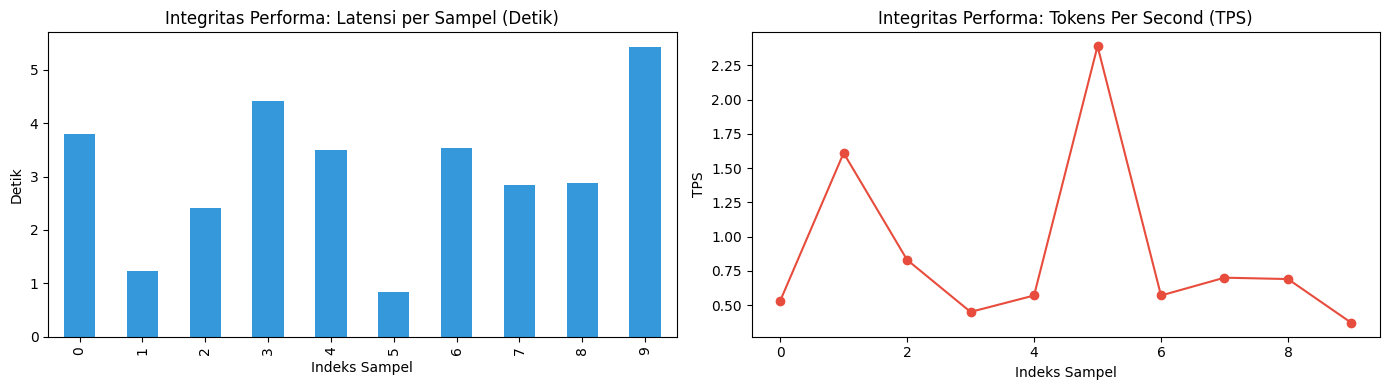

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
df_results['runtime_sec'].plot(kind='bar', color='#3498db', ax=axes[0])
axes[0].set_title('Integritas Performa: Latensi per Sampel (Detik)')
axes[0].set_xlabel('Indeks Sampel')
axes[0].set_ylabel('Detik')

df_results['tps'].plot(kind='line', marker='o', color='#e74c3c', ax=axes[1])
axes[1].set_title('Integritas Performa: Tokens Per Second (TPS)')
axes[1].set_xlabel('Indeks Sampel')
axes[1].set_ylabel('TPS')

plt.tight_layout()
plt.show()

### **8.3 Metric Aggregation**

In [12]:
invalid_rate = (invalid_count / len(results)) * 100
avg_runtime = df_results["runtime_sec"].mean()
avg_tps = df_results["tps"].mean()

print(
    f"[METRICS] total={len(results)} | "
    f"valid={valid_count} | "
    f"invalid={invalid_count} | "
    f"failure_rate={invalid_rate:.1f}%"
)
print(
    f"[METRICS] avg_runtime={avg_runtime:.2f}s | "
    f"avg_tps={avg_tps:.2f}"
)

assert invalid_rate < 20.0, (
    "[INFERENCE] status=FAILED | "
    "error='parse_failure_rate_exceeded' | "
    f"actual={invalid_rate:.1f}% | "
    "threshold=20.0%"
)

[METRICS] total=10 | valid=10 | invalid=0 | failure_rate=0.0%
[METRICS] avg_runtime=3.09s | avg_tps=0.87
